In [4]:
from pyDOE import lhs
from smt.sampling_methods import LHS
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import os
import cv2
import json
import seaborn as sns

import asyncio
import websockets
import base64
from PIL import Image as PILImage, ImageDraw
from IPython.display import display, Image as IPythonImage
from ipywidgets import interact, IntSlider, fixed

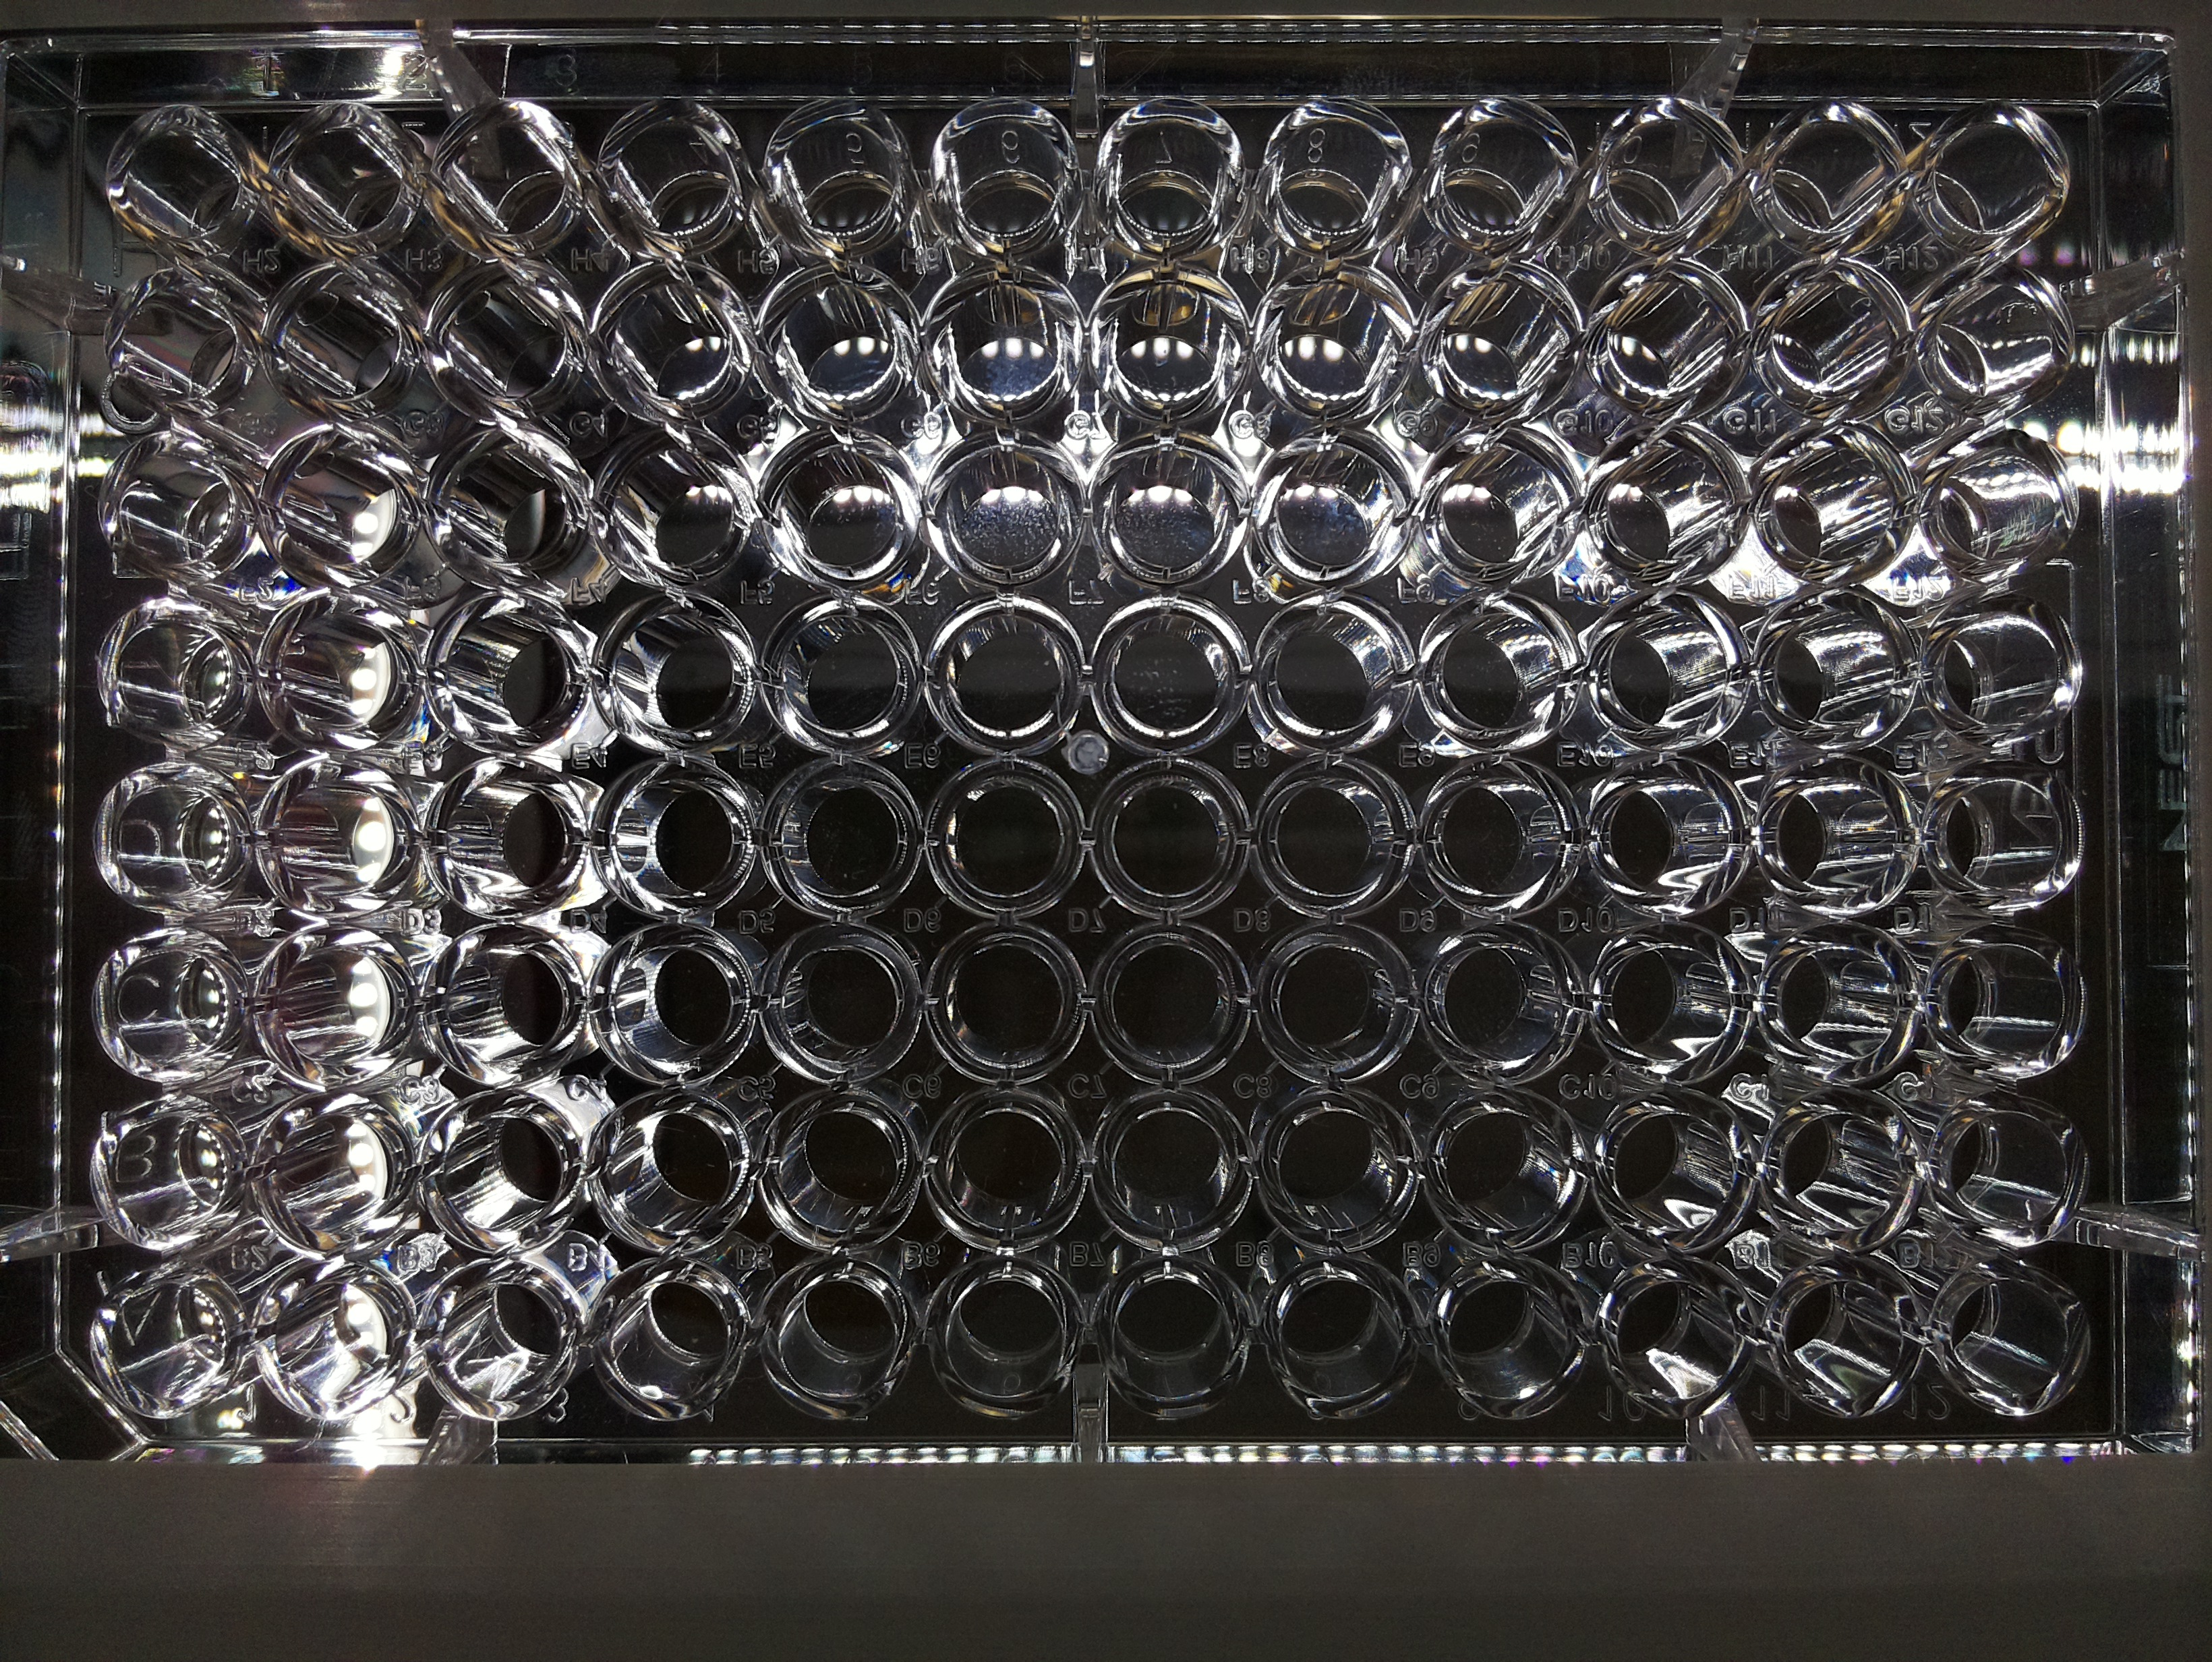

Image captured
Image saved as captured_image.jpg
None


In [5]:
async def capture_photo():
    uri = "ws://172.28.236.86:8765"
    
    async with websockets.connect(uri, max_size=5_000_000) as websocket:
        # send command to capture
        await websocket.send("capture")
        
        # wait for response
        response = await websocket.recv()
        
        try:
            # decode from Base64
            img_data = base64.b64decode(response)
            
            display(IPythonImage(data=img_data, format='jpg'))
            print("Image captured")

            with open("captured_image.jpg", "wb") as f:
                f.write(img_data)
            print("Image saved as captured_image.jpg")

        except Exception as e:
            print("Response:", response)
            print("Exception:", e)

result = await capture_photo()
print(result)

In [6]:
# parameters for bilateral filtering
diameter = 5
sigmaColor = 75
sigmaSpace = 75

image_gray = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
filtered_image = cv2.bilateralFilter(image_gray, diameter, sigmaColor, sigmaSpace)
image_rgb = cv2.imread(image_path)

rows = 8
cols = 12

# define coordinates for top-left and bottom-right grid points
top_left = (265, 278)
bottom_right = (2989, 2006)

x_step = (bottom_right[0] - top_left[0]) / (cols - 1)
y_step = (bottom_right[1] - top_left[1]) / (rows - 1)

expected_grid = []
rgb_values = []

for row in range(rows):
    for col in range(cols):
        x = int(top_left[0] + col * x_step)
        y = int(top_left[1] + row * y_step)
        expected_grid.append((x, y))
        
        # image[row, col] → image[y, x]
        b, g, r = image_rgb[y, x]  
        rgb_values.append([r, g, b]) 

output_grid = image_rgb.copy()

# draw circle
for (x, y) in expected_grid:
    cv2.circle(output_grid, (x, y), 100, (255, 0, 0), 2)

output_grid_rgb = cv2.cvtColor(output_grid, cv2.COLOR_BGR2RGB)

Target color: RGB [120, 150, 200]
Closest match: Well G12 (RGB [144, 148, 151])
Color distance: 54.60

RGB values for all 96 wells:
Well A1: [34, 34, 32]
Well A2: [34, 30, 27]
Well A3: [166, 168, 167]
Well A4: [40, 36, 33]
Well A5: [41, 36, 32]
Well A6: [57, 57, 49]
Well A7: [175, 168, 140]
Well A8: [68, 63, 60]
Well A9: [27, 27, 27]
Well A10: [34, 32, 33]
Well A11: [49, 49, 51]
Well A12: [37, 37, 39]
Well B1: [77, 78, 73]
Well B2: [48, 47, 45]
Well B3: [17, 13, 14]
Well B4: [30, 30, 32]
Well B5: [91, 81, 69]
Well B6: [240, 232, 245]
Well B7: [219, 215, 216]
Well B8: [59, 57, 60]
Well B9: [205, 206, 192]
Well B10: [67, 63, 64]
Well B11: [77, 53, 41]
Well B12: [58, 58, 66]
Well C1: [78, 85, 78]
Well C2: [63, 53, 54]
Well C3: [32, 31, 29]
Well C4: [18, 18, 16]
Well C5: [96, 96, 98]
Well C6: [61, 61, 71]
Well C7: [49, 51, 63]
Well C8: [46, 53, 72]
Well C9: [85, 86, 88]
Well C10: [205, 205, 207]
Well C11: [196, 179, 169]
Well C12: [83, 84, 88]
Well D1: [108, 97, 95]
Well D2: [62, 58, 59]
W

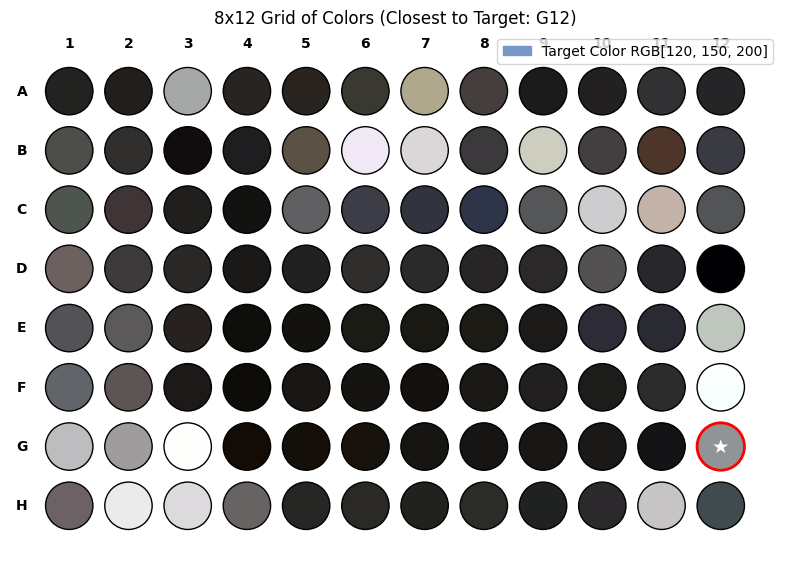

In [11]:
import numpy as np
from matplotlib import pyplot as plt
import math

# Define target color
target_color = [120, 150, 200]  # Example target color - replace with your actual target

image_path = 'captured_image.jpg'
fig, ax = plt.subplots(figsize=(8, 6))  # Increased figure size for labels

# make sure to have exact number of rows and columns
if len(rgb_values) < rows * cols:
    rgb_values += [[0, 0, 0]] * (rows * cols - len(rgb_values))

# Function to calculate color distance (Euclidean distance in RGB space)
def color_distance(color1, color2):
    return math.sqrt(sum((c1 - c2) ** 2 for c1, c2 in zip(color1, color2)))

# Find the well with the closest color to target
min_distance = float('inf')
closest_well_index = -1
closest_well_label = ""

for row in range(rows):
    for col in range(cols):
        index = row * cols + col
        rgb = rgb_values[index]
        
        # Calculate distance to target color
        distance = color_distance(rgb, target_color)
        
        # Keep track of the closest match
        if distance < min_distance:
            min_distance = distance
            closest_well_index = index
            closest_well_label = f"{chr(65 + row)}{col+1}"  # e.g., A1, B2, etc.

# Draw the wells
for row in range(rows):
    for col in range(cols):
        index = row * cols + col
        rgb = rgb_values[index]
        # normalize RGB values to [0, 1]
        color = [val / 255 for val in rgb]
        
        # Determine if this is the closest well
        is_closest = (index == closest_well_index)
        
        # note the y-coordinate is inverted for display
        circle = plt.Circle((col + 0.5, rows - row - 0.5), 0.4, facecolor=color, 
                            edgecolor='red' if is_closest else 'black', 
                            linewidth=2 if is_closest else 1)
        ax.add_patch(circle)
        
        # Mark the closest well with a star or other indicator
        if is_closest:
            ax.text(col + 0.5, rows - row - 0.5, '★', color='white', 
                   ha='center', va='center', fontsize=14, fontweight='bold')

# Add row labels (A-H)
for row in range(rows):
    row_label = chr(65 + row)  # Convert 0-7 to A-H
    ax.text(-0.3, rows - row - 0.5, row_label, va='center', ha='center', 
            fontsize=10, fontweight='bold')

# Add column labels (1-12)
for col in range(cols):
    ax.text(col + 0.5, rows + 0.3, str(col + 1), va='center', ha='center', 
            fontsize=10, fontweight='bold')

# Print RGB values for specific wells and all wells
print(f"Target color: RGB {target_color}")
print(f"Closest match: Well {closest_well_label} (RGB {rgb_values[closest_well_index]})")
print(f"Color distance: {min_distance:.2f}")

# Print RGB values for all 96 wells
print("\nRGB values for all 96 wells:")
for row in range(rows):
    row_label = chr(65 + row)  # Convert 0-7 to A-H
    for col in range(cols):
        index = row * cols + col
        well_label = f"{row_label}{col+1}"  # Well ID (e.g., A1, B2, etc.)
        print(f"Well {well_label}: {rgb_values[index]}")

# Set the plot limits with extra space for labels
ax.set_xlim(-0.5, cols + 0.5)
ax.set_ylim(-0.5, rows + 0.5)
ax.set_aspect('equal')
ax.axis('off')
plt.title(f'8x12 Grid of Colors (Closest to Target: {closest_well_label})')
plt.tight_layout()  # Adjust layout to fit labels

# Add a legend for the target color
target_patch = plt.Rectangle((0, 0), 1, 1, color=[c/255 for c in target_color])
plt.legend([target_patch], [f'Target Color RGB{target_color}'], loc='upper right')

plt.show()